# E — Hybrid plasma models of comets

**Tutorial E1 · Cometary Plasma Modeling series**

The second model family in Goetz et al. (2022, *Space Sci. Rev.* 218:65, Table 5) is the **hybrid** model. Some species are computational particles and the rest is a fluid. In cometary work the usual split is:

* **all ions** (solar-wind H⁺, He²⁺, cometary H₂O⁺, CO₂⁺, …) are **macro-particles** that follow the Lorentz force, so finite-gyroradius effects are kept;
* **electrons** form a **massless, charge-neutralising fluid**, so the code never has to resolve electron gyration or plasma oscillations.

Hybrid codes are the workhorse for **weakly to moderately active comets** like 67P at > 2 au. There the cometary-ion gyroradius (10³–10⁵ km) is larger than the interaction region and fluid models fail (tutorial D, end of Part 2). The Menura code already in this repository (`menura_source/`, Behar et al. 2022) is a hybrid code. This notebook builds a minimal one from scratch so you can see every piece Menura implements at scale.

| Code | Notes | Comet applications |
|---|---|---|
| **A.I.K.E.F.** (Müller et al. 2011), successor of the Bagdonat & Motschmann (2002) cometary code | 3-D, adaptive mesh refinement, CPU/MPI | Bagdonat & Motschmann (2002); Koenders et al. (2013); Rubin et al. (2014) |
| **Menura** (Behar et al. 2022) | 3-D, GPU, turbulent solar-wind input | Comet/solar-wind interaction with a turbulent upstream |
| Other cometary hybrid models | e.g. Gunell et al. (2018) infant bow shock; the semi-analytic model of Behar et al. (2018) is a useful check | 67P at intermediate activity |

> **Learning goals.** (i) Write down the hybrid equation set: ion Newton–Lorentz, electron-fluid Ohm's law, Faraday. (ii) Implement particle-in-cell weighting, the Boris pusher and a sub-cycled field solver. (iii) Reproduce the hallmark kinetic signature of a weak comet: **sideways pickup of cometary ions and opposite deflection of the solar wind**, with little loss of solar-wind energy (Behar et al. 2016; Goetz et al. 2022, Sect. 2.3.1, Fig. 10).

## 1. Equations

**Ions** (each macro-particle $p$, species $s$):
$$ \frac{d\mathbf x_p}{dt} = \mathbf v_p,\qquad \frac{d\mathbf v_p}{dt} = \frac{q_s}{m_s}\big(\mathbf E + \mathbf v_p\times\mathbf B\big). $$

**Moments** deposited on the grid: charge density $n = \sum_s q_s n_s/e$ and ion bulk velocity $\mathbf u_i = \sum_s q_s n_s\mathbf u_s/(e n)$.

**Massless electrons.** The electron momentum equation with $m_e\to 0$ gives the **generalised Ohm's law**:
$$ \mathbf E = -\mathbf u_i\times\mathbf B + \frac{\mathbf J\times\mathbf B}{e n} - \frac{\nabla p_e}{e n} + \eta\mathbf J,\qquad \mathbf J = \nabla\times\mathbf B/\mu_0 . $$
The terms are, in order: convective, Hall, ambipolar (electron pressure) and resistive. We take isothermal electrons, $p_e = n k_B T_e$.

**Faraday's law** closes the system: $\partial_t\mathbf B = -\nabla\times\mathbf E$.

### Units
We use the standard hybrid normalisation: upstream density $n_0$, field $B_0$, proton mass $m_p$. Lengths are in ion inertial lengths $d_i = c/\omega_{pi}$, times in inverse proton gyrofrequencies $\Omega_p^{-1}$, and speeds in the Alfvén speed $v_A$. Then $\mu_0 = e = m_p = 1$.

| Quantity | Code value | Physical value (n₀ = 1 cm⁻³, B₀ = 2 nT, ~2.5 au) |
|---|---|---|
| $d_i$ | 1 | 228 km |
| $\Omega_p^{-1}$ | 1 | 5.2 s |
| $v_A$ | 1 | 44 km/s |
| Solar-wind speed | 8 | 350 km/s |
| H₂O⁺ pickup gyroradius $m_w V/(eB_0)$ | 18 × 8 = 144 | ≈ 33,000 km |

### Geometry: a 2-D "B out of plane" model
For speed we simulate the plane containing the solar-wind flow ($-\hat x$) and the convective electric field, with $\mathbf B = B_z\hat z$ perpendicular to it. Then:
* upstream $\mathbf E = -\mathbf u\times\mathbf B = -V B_0\,\hat y$, so cometary ions are accelerated toward $-y$;
* $\mathbf J = (\partial_y B_z, -\partial_x B_z, 0)$ lies in the plane and only $B_z$ evolves.

This reduced geometry keeps pickup gyration, mass loading and magnetic pile-up. It drops whistler waves (they need $\mathbf k\cdot\mathbf B\neq0$), which makes the scheme very robust: a deliberate teaching choice. Codes like Menura and A.I.K.E.F. are fully 3-D.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import time
plt.rcParams.update({'figure.dpi': 110})
rng = np.random.default_rng(1)

## 2. Building blocks

### 2a. The Boris pusher, with a test-particle check
The Boris scheme (Birdsall & Langdon 1991) is the standard particle pusher in hybrid and PIC codes, including Menura. It conserves energy exactly in a pure magnetic field. For B along $z$ the rotation step simplifies to two scalar operations.

Check: a proton starting at rest in uniform $\mathbf B = \hat z$ and $\mathbf E = -V\hat y$ should trace a cycloid. Its guiding centre should drift at the $\mathbf E\times\mathbf B$ velocity $(-V, 0)$, and its speed should never exceed $2V$.

mean drift velocity = (-8.012, +0.000)   expected (-8.0, 0)
max speed / (2V) = 1.0000   (pickup ions reach up to twice the flow speed)


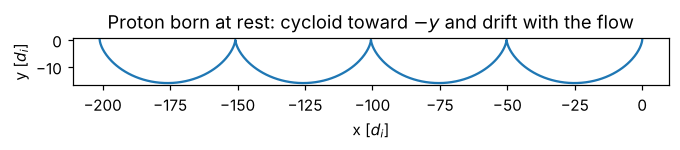

In [2]:
def boris(vx, vy, ex, ey, bz, qm, dt):
    """Boris push for B = bz * z_hat (2-D, in-plane velocities)."""
    h = 0.5*dt*qm
    vx = vx + h*ex; vy = vy + h*ey                    # half electric kick
    t = h*bz; s = 2*t/(1 + t**2)                       # magnetic rotation
    vpx = vx + vy*t; vpy = vy - vx*t
    vx = vx + vpy*s; vy = vy - vpx*s
    return vx + h*ex, vy + h*ey                        # second half electric kick

V, dt_test = 8.0, 0.05
vx = vy = 0.0; xs, ys, sp = [0.0], [0.0], []
for k in range(int(4*2*np.pi/dt_test)):               # four gyro-periods
    vx, vy = boris(vx, vy, 0.0, -V, 1.0, 1.0, dt_test)
    xs.append(xs[-1]+vx*dt_test); ys.append(ys[-1]+vy*dt_test); sp.append(np.hypot(vx, vy))
T = len(sp)*dt_test
print(f'mean drift velocity = ({xs[-1]/T:+.3f}, {ys[-1]/T:+.3f})   expected (-{V}, 0)')
print(f'max speed / (2V) = {max(sp)/(2*V):.4f}   (pickup ions reach up to twice the flow speed)')
plt.figure(figsize=(7, 2.4)); plt.plot(xs, ys); plt.gca().set_aspect('equal')
plt.xlabel('x [$d_i$]'); plt.ylabel('y [$d_i$]'); plt.title('Proton born at rest: cycloid toward $-y$ and drift with the flow'); plt.show()

### 2b. Grid, particle weighting and the field solver
* **Cloud-in-cell (CIC)** weighting: each particle shares its weight among the 4 nearest cell centres. The same stencil is used to gather fields back to the particle.
* Moments get a light binomial **smoothing** pass. Most production hybrid codes filter or smooth in some way to suppress grid-scale noise.
* Fields are advanced with **sub-cycling**: several mid-point (RK2) Faraday steps per particle step, holding $n$ and $\mathbf u_i$ fixed. Menura uses 11 sub-cycles of the same kind of predictor–corrector scheme (see the Menura tutorials in `B_menura_guide/`).
* **Boundaries**: solar wind is injected at $x = L_x$ (the sunward side) and particles leaving at $x = 0$ or $x = L_x$ are removed. The $y$ direction is periodic for protons and fields. Cometary ions crossing a $y$ boundary are removed, so they cannot re-enter upstream of the comet.

In [3]:
# ---------------- simulation parameters (normalised units) ----------------
Lx = Ly = 240.0; dx = 2.0; Nx, Ny = int(Lx/dx), int(Ly/dx)
V, beta_p, beta_e = 8.0, 0.5, 0.5
vth = np.sqrt(beta_p/2); Te = beta_e/2              # beta = 2 mu0 n kT / B^2 with mu0 = n = B = 1
eta, dt, nsub, ppc = 0.0, 0.05, 4, 10
wp = dx*dx/ppc                                      # proton macro-particle weight (density x area)

# comet: Haser-like ionisation source centred at (xc, yc)
xc, yc, r0, rmax = 0.6*Lx, 0.5*Ly, 2.0, 100.0
mw = 18.0                                           # H2O+ mass in m_p
Ndot = 15.0                                         # ion production rate [n0 d_i^2 Omega_p] (2-D mass-loading strength)
nw_step = 20; ww = Ndot*dt/nw_step                  # macro-particles per step and their weight
nsteps = 800

def deposit(P):
    gx = P['x']/dx - 0.5; gy = P['y']/dx - 0.5
    i = np.floor(gx).astype(int); j = np.floor(gy).astype(int); fx, fy = gx-i, gy-j
    n = np.zeros(Nx*Ny); jx = np.zeros(Nx*Ny); jy = np.zeros(Nx*Ny)
    for di, dj, w in [(0,0,(1-fx)*(1-fy)), (1,0,fx*(1-fy)), (0,1,(1-fx)*fy), (1,1,fx*fy)]:
        idx = np.clip(i+di, 0, Nx-1)*Ny + (j+dj) % Ny; ww_ = w*P['w']
        n += np.bincount(idx, ww_, Nx*Ny); jx += np.bincount(idx, ww_*P['vx'], Nx*Ny); jy += np.bincount(idx, ww_*P['vy'], Nx*Ny)
    out = [a.reshape(Nx, Ny)/(dx*dx) for a in (n, jx, jy)]
    for a in out: a[0] = a[1]; a[-1] = a[-2]        # fill half-empty boundary cells
    return out

def smooth(a):
    b = a.copy(); b[1:-1] = 0.25*a[:-2] + 0.5*a[1:-1] + 0.25*a[2:]
    return 0.25*np.roll(b, 1, 1) + 0.5*b + 0.25*np.roll(b, -1, 1)

def moments(P, nfloor=0.05):
    n, jx, jy = deposit(P); n = smooth(np.maximum(n, nfloor))
    return n, smooth(jx)/n, smooth(jy)/n

ddx = lambda a: np.gradient(a, dx, axis=0)
ddy = lambda a: (np.roll(a, -1, 1) - np.roll(a, 1, 1))/(2*dx)

def efield(Bz, n, ux, uy):
    """Generalised Ohm's law for B = Bz z_hat, in-plane E."""
    Jx, Jy = ddy(Bz), -ddx(Bz); pe = n*Te
    Ex = -uy*Bz + Jy*Bz/n - ddx(pe)/n + eta*Jx       # convective + Hall + ambipolar + resistive
    Ey =  ux*Bz - Jx*Bz/n - ddy(pe)/n + eta*Jy
    return Ex, Ey

def advance_B(Bz, n, ux, uy, dtt):
    h = dtt/nsub
    for _ in range(nsub):                             # sub-cycled mid-point Faraday update
        Ex, Ey = efield(Bz, n, ux, uy); Bh = Bz - 0.5*h*(ddx(Ey) - ddy(Ex)); Bh[-1] = 1.0
        Ex, Ey = efield(Bh, n, ux, uy); Bz = Bz - h*(ddx(Ey) - ddy(Ex));     Bz[-1] = 1.0
    return Bz

def gather(f, P):
    gx = P['x']/dx - 0.5; gy = P['y']/dx - 0.5
    i = np.floor(gx).astype(int); j = np.floor(gy).astype(int); fx, fy = gx-i, gy-j
    return sum(w*f[np.clip(i+di, 0, Nx-1), (j+dj) % Ny]
               for di, dj, w in [(0,0,(1-fx)*(1-fy)), (1,0,fx*(1-fy)), (0,1,(1-fx)*fy), (1,1,fx*fy)])

def new_particles(x, y, vx, vy, qm, w):
    k = len(x); return {'x': x, 'y': y, 'vx': vx, 'vy': vy, 'qm': np.full(k, qm), 'w': np.full(k, w)}

### 2c. Sources: solar-wind injection and cometary ionisation
New H₂O⁺ ions are created **at rest** in the comet frame, the neutral speed being ≈ 1 km/s ≪ $V$. Their positions follow a Haser-like profile, $\dot n \propto 1/(r^2+r_0^2)$. In 2-D the radial distribution $P(r)\propto r/(r^2+r_0^2)$ can be sampled exactly by inverse-CDF. Ionisation could be made position- or time-dependent, as production codes do for photo- vs. electron-impact ionisation.

In [4]:
def ionise():
    s = rng.uniform(size=nw_step)
    r = r0*np.sqrt(((rmax**2 + r0**2)/r0**2)**s - 1)        # inverse CDF of P(r) ~ r/(r^2+r0^2)
    th = rng.uniform(0, 2*np.pi, nw_step)
    return new_particles(xc + r*np.cos(th), yc + r*np.sin(th), np.zeros(nw_step), np.zeros(nw_step), 1/mw, ww)

def inject_solar_wind():
    k = int(round(V*dt*Ly/wp))
    return new_particles(Lx - rng.uniform(0, V*dt, k), rng.uniform(0, Ly, k),
                         -V + vth*rng.standard_normal(k), vth*rng.standard_normal(k), 1.0, wp)

def merge(P, *Q): return {k: np.concatenate([P[k]] + [q[k] for q in Q]) for k in P}

## 3. Main loop
Each step: (1) add new ions; (2) compute $\mathbf E$ from Ohm's law; (3) Boris-push all ions; (4) remove escaping particles; (5) re-deposit moments; (6) advance $B_z$ with the sub-cycled Faraday solver using time-centred density. Expect about 1–2 minutes on a laptop.

In [5]:
N0 = Nx*Ny*ppc
P = new_particles(rng.uniform(0, Lx, N0), rng.uniform(0, Ly, N0),
                  -V + vth*rng.standard_normal(N0), vth*rng.standard_normal(N0), 1.0, wp)
Bz = np.ones((Nx, Ny)); n, ux, uy = moments(P)
hist = {'t': [], 'vy_p': [], 'vy_w': [], 'speed_p': []}
t0 = time.time()
for it in range(nsteps + 1):
    P = merge(P, ionise(), inject_solar_wind())
    Ex, Ey = efield(Bz, n, ux, uy)
    P['vx'], P['vy'] = boris(P['vx'], P['vy'], gather(Ex, P), gather(Ey, P), gather(Bz, P), P['qm'], dt)
    P['x'] += P['vx']*dt; P['y'] += P['vy']*dt
    keep = (P['x'] > 0) & (P['x'] < Lx) & ~((P['qm'] < 1) & ((P['y'] < 0) | (P['y'] >= Ly)))
    P = {k: v[keep] for k, v in P.items()}; P['y'] %= Ly
    n2, ux2, uy2 = moments(P)
    Bz = advance_B(Bz, 0.5*(n + n2), ux2, uy2, dt)
    n, ux, uy = n2, ux2, uy2
    if it % 20 == 0:
        pr = P['qm'] == 1; box = (abs(P['x']-xc) < 40) & (abs(P['y']-yc) < 40)
        hist['t'].append(it*dt)
        hist['vy_p'].append(P['vy'][pr & box].mean()); hist['vy_w'].append(P['vy'][~pr].mean() if (~pr).any() else 0)
        hist['speed_p'].append(np.hypot(P['vx'], P['vy'])[pr & box].mean())
    if it % 200 == 0:
        print(f'step {it:4d}  t = {it*dt:5.1f}  particles = {len(P["x"]):,}  max Bz = {Bz.max():.2f}  ({time.time()-t0:.0f} s)')

step    0  t =   0.0  particles = 144,028  max Bz = 1.00  (0 s)


step  200  t =  10.0  particles = 147,964  max Bz = 2.09  (29 s)


step  400  t =  20.0  particles = 152,018  max Bz = 2.71  (62 s)


step  600  t =  30.0  particles = 157,913  max Bz = 2.79  (93 s)


step  800  t =  40.0  particles = 167,249  max Bz = 3.28  (126 s)


## 4. Results

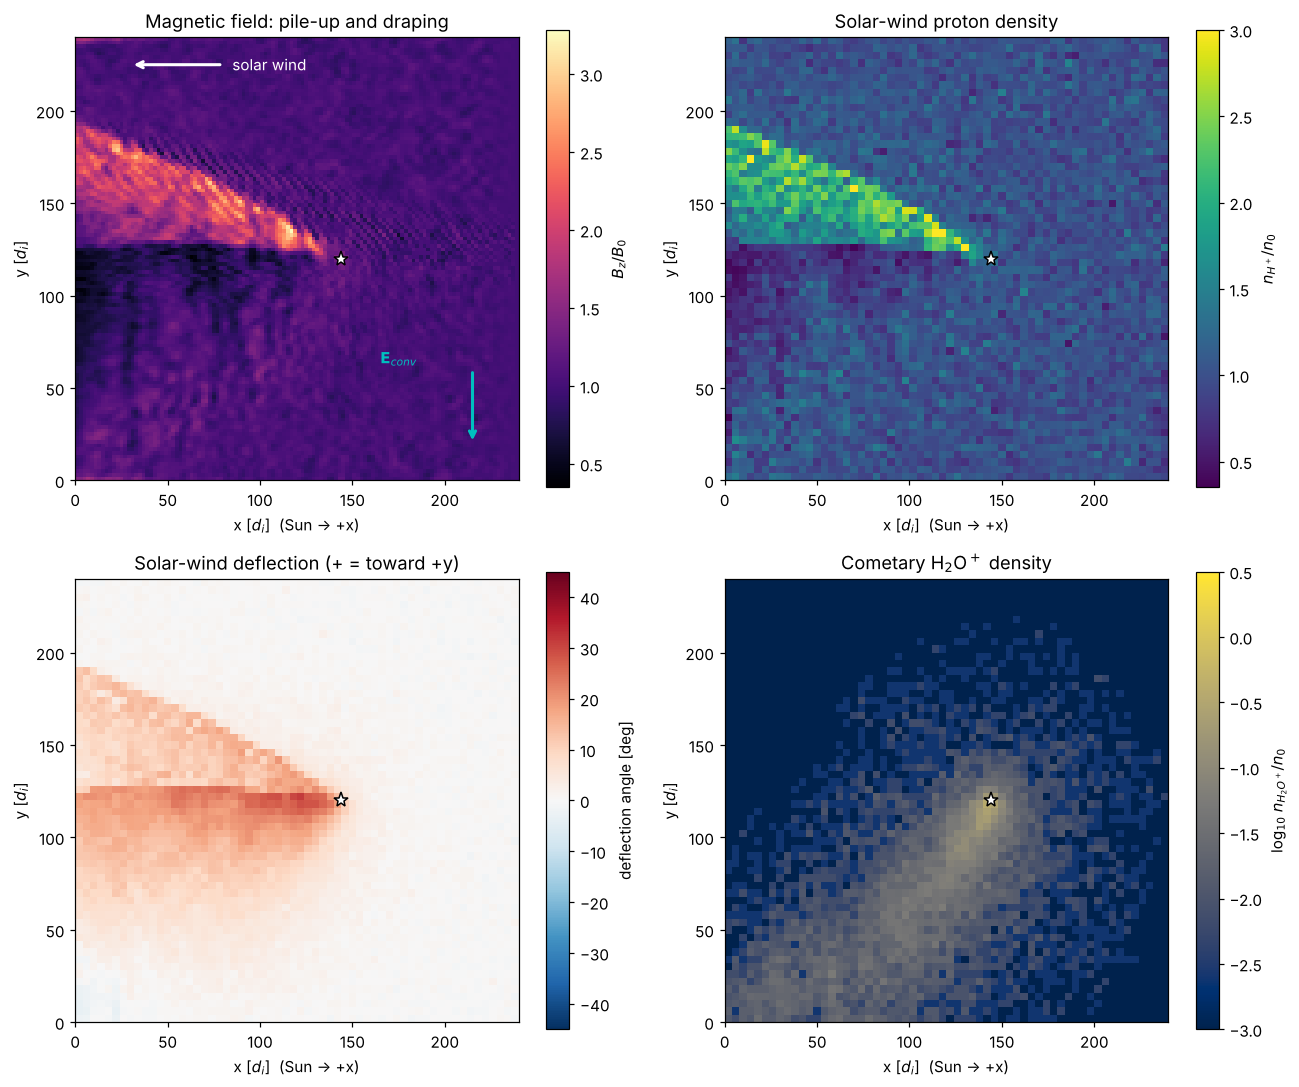

In [6]:
pr = P['qm'] == 1
nb = 60; rng2 = [[0, Lx], [0, Ly]]
def binned(mask, wts=None):
    return np.histogram2d(P['x'][mask], P['y'][mask], bins=nb, range=rng2, weights=wts)[0]
cnt = binned(pr); Hvx = binned(pr, P['vx'][pr]); Hvy = binned(pr, P['vy'][pr])
dens_p = binned(pr, P['w'][pr])/((Lx/nb)*(Ly/nb))
defl = np.degrees(np.arctan2(Hvy, -Hvx))
dens_w = binned(~pr, P['w'][~pr])/((Lx/nb)*(Ly/nb))
ext = [0, Lx, 0, Ly]

fig, ax = plt.subplots(2, 2, figsize=(12, 10))
im = ax[0,0].imshow(Bz.T, origin='lower', extent=ext, cmap='magma'); plt.colorbar(im, ax=ax[0,0], label='$B_z/B_0$')
ax[0,0].set_title('Magnetic field: pile-up and draping')
im = ax[0,1].imshow(dens_p.T, origin='lower', extent=ext, cmap='viridis', vmax=3); plt.colorbar(im, ax=ax[0,1], label='$n_{H^+}/n_0$')
ax[0,1].set_title('Solar-wind proton density')
im = ax[1,0].imshow(defl.T, origin='lower', extent=ext, cmap='RdBu_r', vmin=-45, vmax=45); plt.colorbar(im, ax=ax[1,0], label='deflection angle [deg]')
ax[1,0].set_title('Solar-wind deflection (+ = toward +y)')
im = ax[1,1].imshow(np.log10(dens_w.T + 1e-4), origin='lower', extent=ext, cmap='cividis', vmin=-3, vmax=0.5)
plt.colorbar(im, ax=ax[1,1], label='log$_{10}$ $n_{H_2O^+}/n_0$'); ax[1,1].set_title('Cometary H$_2$O$^+$ density')
for a in ax.flat:
    a.plot(xc, yc, 'w*', ms=10, mec='k'); a.set_xlabel('x [$d_i$]  (Sun → +x)'); a.set_ylabel('y [$d_i$]')
ax[0,0].annotate('', xy=(30, 225), xytext=(80, 225), arrowprops=dict(color='w', arrowstyle='->', lw=2))
ax[0,0].text(85, 222, 'solar wind', color='w')
ax[0,0].annotate('', xy=(215, 20), xytext=(215, 60), arrowprops=dict(color='c', arrowstyle='->', lw=2))
ax[0,0].text(165, 63, '$\\mathbf{E}_{conv}$', color='c')
plt.tight_layout(); plt.show()

**Reading the maps.**
* **Opposite deflections.** Cometary ions (bottom right) are picked up along the convective electric field ($-y$) on cycloidal paths whose size is set by their 144-$d_i$ gyroradius. The solar-wind protons (bottom left) are deflected the **opposite way**, toward $+y$. This is the momentum-balance picture of Behar et al. (2016, 2018) and the "kinetic regime" panel of Goetz et al. (2022) Fig. 10. A fluid model would give a symmetric picture.
* **Asymmetric pile-up.** The magnetic pile-up (top left) and proton compression (top right) sit only on the $+y$ flank, where deflected protons pile into a one-sided, Mach-cone-like front.
* **Deflected more than slowed.** The numbers below show the protons near the nucleus turned by about 7° on average (≈25° locally, bottom-left map) while losing under 10 % of their speed. Downstream on the $-y$ side a proton-depleted, low-field region forms where flow has been diverted away. Rosetta saw the same pattern at 67P: large deflection angles with modest loss of kinetic energy (Behar et al. 2016; Goetz et al. 2022, Fig. 11). The momentum given to the cometary ions mostly rotates the solar-wind flow rather than braking it.
* **No shock yet.** At this mass loading there is no closed bow shock, only a compressive, Mach-cone-like structure. Gunell et al. (2018) call the structure that forms at somewhat higher activity an "infant bow shock". Try raising `Ndot` (Exercise 1).

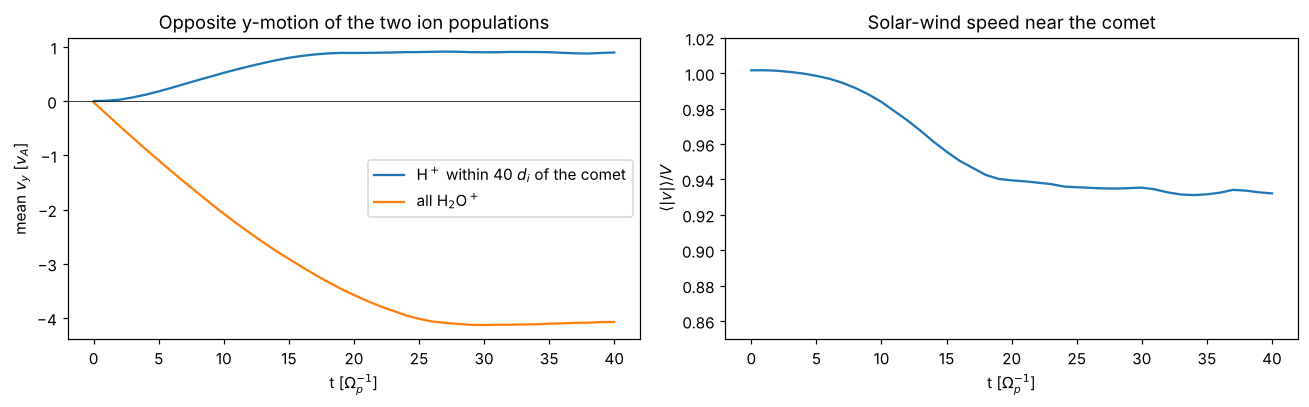

Mean solar-wind deflection within 40 d_i of the nucleus: +7.0 deg
Mean proton speed there: 0.93 V


In [7]:
t = np.array(hist['t'])
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(t, hist['vy_p'], label='H$^+$ within 40 $d_i$ of the comet')
ax[0].plot(t, hist['vy_w'], label='all H$_2$O$^+$')
ax[0].axhline(0, color='k', lw=0.5); ax[0].set(xlabel='t [$\\Omega_p^{-1}$]', ylabel='mean $v_y$ [$v_A$]', title='Opposite y-motion of the two ion populations')
ax[0].legend()
ax[1].plot(t, np.array(hist['speed_p'])/V)
ax[1].set(xlabel='t [$\\Omega_p^{-1}$]', ylabel='$\\langle|v|\\rangle / V$', title='Solar-wind speed near the comet', ylim=(0.85, 1.02))
plt.tight_layout(); plt.show()

near = pr & (abs(P['x']-xc) < 40) & (abs(P['y']-yc) < 40)
ang = np.degrees(np.arctan2(P['vy'][near].mean(), -P['vx'][near].mean()))
print(f'Mean solar-wind deflection within 40 d_i of the nucleus: {ang:+.1f} deg')
print(f'Mean proton speed there: {np.hypot(P["vx"][near], P["vy"][near]).mean()/V:.2f} V')

## 5. From this notebook to Menura / A.I.K.E.F.

| This tutorial | Production hybrid codes |
|---|---|
| 2-D, $\mathbf B\perp$ plane (no whistlers) | Full 3-D; whistler waves set the time step (Menura sub-cycles Faraday 11 times per particle step) |
| Collocated grid, central differences, binomial smoothing | Staggered (Yee-like) grids or adaptive meshes (A.I.K.E.F.); current-advance or predictor–corrector methods |
| Constant ionisation, one heavy species | Photo- and electron-impact ionisation, charge exchange, several cometary species |
| Isothermal electrons | Adiabatic or polytropic electron fluid; some codes carry separate cometary and solar-wind electron fluids |
| ~10⁵ particles, numpy | 10⁸–10¹⁰ particles on GPUs (Menura) or MPI clusters |

The mapping to Menura's source is direct: `boris()` ↔ the Boris pusher kernel, `efield()` ↔ the Ohm's-law kernel, `advance_B()` ↔ the CAM / sub-cycled Faraday loop (`nb_sub_cycles`). See `B_menura_guide/02_code_structure_walkthrough.md`.

### Exercises
1. Double `Ndot`. Does the deflection angle saturate? Do protons start to be reflected (deflection > 90°)? Compare with the Rosetta trend in Goetz et al. (2022) Fig. 11.
2. Flip the sign of $B_0$ (set the initial `Bz` and the boundary value to −1). Which way do the cometary ions go now?
3. Set `beta_e = 0` to switch off the ambipolar term. What changes near the nucleus?
4. Replace water ions (`mw = 18`) by CO⁺ (`mw = 28`), as for comet 29P at 6 au. How does the larger gyroradius change the asymmetry?
5. *(Advanced)* Add a second sub-population of solar-wind He²⁺ (q/m = 1/2) and compare its deflection with the protons'.

## References
* Bagdonat, T., & Motschmann, U. (2002). From a weak to a strong comet – 3D global hybrid simulation studies. *Earth, Moon, and Planets*, 90, 305–321.
* Behar, E., et al. (2016). Mass-loading of the solar wind at 67P/Churyumov-Gerasimenko: Observations and modelling. *A&A*, 596, A42.
* Behar, E., et al. (2016). Mass loading at 67P/Churyumov-Gerasimenko: A case study. *GRL*, 43, 1411–1418.
* Behar, E., et al. (2018). Solar wind dynamics around a comet: A 2D semi-analytical kinetic model. *A&A*, 620, A35.
* Behar, E., Fatemi, S., Henri, P., & Holmström, M. (2022). Menura: a code for simulating the interaction between a turbulent solar wind and solar system bodies. *Ann. Geophys.*, 40, 281–297. https://doi.org/10.5194/angeo-40-281-2022
* Birdsall, C. K., & Langdon, A. B. (1991). *Plasma Physics via Computer Simulation*. IOP Publishing.
* Goetz, C., et al. (2022). The plasma environment of comet 67P/Churyumov-Gerasimenko. *Space Sci. Rev.*, 218, 65.
* Gunell, H., et al. (2018). The infant bow shock: a new frontier at a weak activity comet. *A&A*, 619, L2.
* Koenders, C., et al. (2013). Revisiting cometary bow shock positions. *Planet. Space Sci.*, 87, 85–95.
* Müller, J., et al. (2011). A.I.K.E.F.: Adaptive hybrid model for space plasma simulations. *Comput. Phys. Commun.*, 182, 946–966.
* Rubin, M., et al. (2014). Plasma environment of a weak comet – Predictions for comet 67P from multifluid-MHD and hybrid models. *Icarus*, 242, 38–49.
* Winske, D., & Omidi, N. (1996). A nonspecialist's guide to kinetic simulations of space plasmas. *JGR*, 101(A8), 17287–17303.